<a href="https://colab.research.google.com/github/RZchive/Probstat_UTS/blob/main/Statistika_Deskriptif_Pola_Tidur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Statistika Deskriptif & Visualisasi Data
## Pola Tidur dan Performa Akademik Mahasiswa

**Cara pakai di Google Colab**
1. Jalankan sel dari atas ke bawah (menu *Runtime → Run all*, atau tekan `Shift + Enter` per sel).
2. Saat sel **"Muat data"** dijalankan, klik *Choose Files* lalu pilih file `3TIE_Kelompok5_PolaTidurMahasiswa.xlsx`.
3. Setiap chart ada di sel tersendiri, jadi bisa dijalankan atau diubah satu per satu.

**Isi notebook**
- Bagian 0: Persiapan dan muat data
- Bagian 1: Statistika deskriptif (numerik, ordinal/Likert, kategorik, outlier)
- Bagian 2: 11 chart (profil responden, pola tidur, performa akademik, hubungan antarvariabel)
- Bagian 3: Unduh semua chart

## Bagian 0 — Persiapan

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from IPython.display import display
import os

# Tampilan umum
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)

# Folder untuk menyimpan gambar
os.makedirs("grafik", exist_ok=True)
def simpan(nama):
    plt.savefig(f"grafik/{nama}.png", dpi=200, bbox_inches="tight")

### Muat data

In [ ]:
# Di Google Colab: muncul tombol upload. Di komputer lokal: pakai nama file di bawah.
try:
    from google.colab import files
    uploaded = files.upload()
    FILE = list(uploaded.keys())[0]
except ImportError:
    FILE = "3TIE_Kelompok5_PolaTidurMahasiswa.xlsx"

d = pd.read_excel(FILE, sheet_name="Data_Bersih")

# Hapus data pribadi (tidak diperlukan untuk analisis)
d = d.drop(columns=["email"], errors="ignore")

print("Jumlah responden :", d.shape[0])
print("Jumlah variabel  :", d.shape[1])
print("Nilai kosong     :", int(d.isna().sum().sum()))
d.head()

Saving 3TIE_Kelompok5_PolaTidurMahasiswa.xlsx to 3TIE_Kelompok5_PolaTidurMahasiswa.xlsx
Jumlah responden : 100
Jumlah variabel  : 36
Nilai kosong     : 0


,id_responden,waktu_isi,jenis_kelamin,usia_tahun,program_studi,semester,aktif_kuliah,durasi_tidur_jam,jam_mulai_tidur,jam_bangun,hari_tidur_lewat_00,kali_terbangun,hari_tidur_siang,durasi_tidur_siang_menit,kualitas_tidur,sulit_tidur,jam_belajar_per_hari,konsumsi_kafein_kali,gadget_sebelum_tidur,durasi_gadget_menit,faktor_tidur_larut,tingkat_lelah_kuliah,sering_mengantuk,sulit_konsentrasi,kurang_semangat,p1_ikut_kuliah_baik,p2_konsentrasi_materi,p3_tugas_tepat_waktu,p4_paham_materi,p5_capai_target,p6_semangat_kuliah,p7_atur_waktu,jumlah_tugas_diberikan,tugas_tepat_waktu,hari_kuliah_sesuai_jadwal,hari_produktif
0,R001,2026-10-05 08:52:01.129,Perempuan,22,Akuntansi Perpajakan,5,1,7.00,21:30:00,05:10:00,0,1,1.00,420.00,4,1,15.00,0.00,1,180,Bermain handphone atau media sosial,3,4,4,3,3,4,5,3,4,4,4,0.00,0.00,0.00,0.00
1,R002,2026-10-05 08:56:10.675,Laki-laki,20,Teknologi Rekayasa Mekatronika,5,1,5.00,01:00:00,07:30:00,6,6,7.00,300.00,3,3,5.00,7.00,1,300,Lainnya,4,3,4,4,3,3,4,4,4,3,3,0.00,0.00,0.00,0.00
2,R003,2026-10-05 08:58:51.048,Perempuan,20,Akuntansi Perpajakan,5,1,3.00,04:30:00,06:00:00,7,2,3.00,180.00,1,5,3.00,7.00,1,120,Bermain handphone atau media sosial,3,3,4,4,3,3,3,3,3,3,2,0.00,0.00,0.00,0.00
3,R004,2026-10-05 09:01:26.234,Perempuan,20,Sistem Informasi,5,0,7.00,12:00:00,07:00:00,2,0,3.00,0.00,3,3,2.00,3.00,1,120,Menonton hiburan,3,3,3,3,3,3,3,3,3,3,3,5.00,5.00,5.00,0.00
4,R005,2026-10-05 09:04:06.939,Perempuan,20,Teknologi Rekayasa Mekatronika,5,1,5.00,00:00:00,05:00:00,5,2,6.00,0.00,3,2,3.00,7.00,1,60,Mengerjakan tugas kuliah,2,2,3,2,5,4,5,4,4,4,4,1.00,1.00,5.00,0.00


### Siapkan variabel turunan
- `skor_performa`: rata-rata jawaban p1–p7 (makin tinggi = performa akademik makin baik)
- `kategori_kualitas`: kualitas tidur dikelompokkan jadi Buruk / Sedang / Baik

In [ ]:
# Kelompok variabel
kol_numerik = [
    "usia_tahun", "durasi_tidur_jam", "hari_tidur_lewat_00", "kali_terbangun",
    "hari_tidur_siang", "durasi_tidur_siang_menit", "jam_belajar_per_hari",
    "konsumsi_kafein_kali", "durasi_gadget_menit", "jumlah_tugas_diberikan",
    "tugas_tepat_waktu", "hari_kuliah_sesuai_jadwal", "hari_produktif",
]
kol_ordinal = [
    "kualitas_tidur", "sulit_tidur", "tingkat_lelah_kuliah", "sering_mengantuk",
    "sulit_konsentrasi", "kurang_semangat",
]
kol_likert = ["p1_ikut_kuliah_baik", "p2_konsentrasi_materi", "p3_tugas_tepat_waktu",
              "p4_paham_materi", "p5_capai_target", "p6_semangat_kuliah", "p7_atur_waktu"]
kol_kategorik = ["jenis_kelamin", "program_studi", "semester", "aktif_kuliah",
                 "gadget_sebelum_tidur", "faktor_tidur_larut"]

# Label Likert yang lebih mudah dibaca (silakan ubah sesuai kuesioner)
label_likert = {
    "p1_ikut_kuliah_baik":   "Mengikuti kuliah dengan baik",
    "p2_konsentrasi_materi": "Berkonsentrasi pada materi",
    "p3_tugas_tepat_waktu":  "Mengumpulkan tugas tepat waktu",
    "p4_paham_materi":       "Memahami materi",
    "p5_capai_target":       "Mencapai target belajar",
    "p6_semangat_kuliah":    "Bersemangat mengikuti kuliah",
    "p7_atur_waktu":         "Mengatur waktu dengan baik",
}

# Variabel turunan
d["skor_performa"] = d[kol_likert].mean(axis=1)
d["kategori_kualitas"] = pd.cut(
    d["kualitas_tidur"], bins=[0, 2, 3, 5],
    labels=["Buruk (1–2)", "Sedang (3)", "Baik (4–5)"]
)
print("skor_performa dibuat. Rata-rata:", round(d["skor_performa"].mean(), 2))

skor_performa dibuat. Rata-rata: 3.55


## Bagian 1 — Statistika Deskriptif

### 1.1 Variabel numerik
Ukuran yang dihitung: rata-rata, median, modus, standar deviasi, min, max, Q1, Q3, IQR, dan skewness.

**Cara membaca:** jika *rata-rata* jauh berbeda dari *median*, atau skewness jauh dari 0, data miring dan biasanya ada outlier. Dalam kasus itu, lebih baik laporkan median.

In [ ]:
desk_num = pd.DataFrame({
    "n": d[kol_numerik].count(),
    "rata_rata": d[kol_numerik].mean(),
    "median": d[kol_numerik].median(),
    "modus": [d[c].mode().iloc[0] for c in kol_numerik],
    "std_dev": d[kol_numerik].std(),
    "min": d[kol_numerik].min(),
    "Q1": d[kol_numerik].quantile(0.25),
    "Q3": d[kol_numerik].quantile(0.75),
    "max": d[kol_numerik].max(),
    "skewness": d[kol_numerik].skew(),
})
desk_num["IQR"] = desk_num["Q3"] - desk_num["Q1"]
desk_num = desk_num[["n", "rata_rata", "median", "modus", "std_dev",
                     "min", "Q1", "Q3", "max", "IQR", "skewness"]]
display(desk_num)

,n,rata_rata,median,modus,std_dev,min,Q1,Q3,max,IQR,skewness
usia_tahun,100,19.81,20.00,20.00,1.17,17.00,19.00,20.00,23.00,1.00,0.19
durasi_tidur_jam,100,5.18,5.00,5.00,1.34,2.00,4.00,6.00,8.00,2.00,0.03
hari_tidur_lewat_00,100,4.02,4.00,7.00,2.64,0.00,2.00,7.00,7.00,5.00,-0.26
kali_terbangun,100,1.85,1.00,0.00,2.06,0.00,0.00,3.00,7.00,3.00,1.09
hari_tidur_siang,100,2.25,2.00,0.00,2.02,0.00,0.00,3.00,7.00,3.00,0.73
durasi_tidur_siang_menit,100,92.28,120.00,120.00,76.54,0.00,16.88,127.50,420.00,110.62,0.87
jam_belajar_per_hari,100,3.70,3.25,3.00,2.22,0.00,2.50,4.62,15.00,2.12,2.20
konsumsi_kafein_kali,100,3.73,2.00,0.00,5.36,0.00,0.00,5.00,35.00,5.00,2.94
durasi_gadget_menit,100,139.34,110.00,120.00,141.01,0.00,33.75,180.00,600.00,146.25,1.69
jumlah_tugas_diberikan,100,5.06,5.00,5.00,3.15,0.00,3.00,7.00,17.00,4.00,0.61


### 1.2 Variabel ordinal dan Likert (skor 1–5)
Untuk data ordinal, **median dan modus** adalah ukuran utama. Rata-rata dan SD ditampilkan sebagai pelengkap.

In [ ]:
kol_skala = kol_ordinal + kol_likert + ["skor_performa"]

desk_ord = pd.DataFrame({
    "n": d[kol_skala].count(),
    "median": d[kol_skala].median(),
    "modus": [d[c].mode().iloc[0] for c in kol_skala],
    "rata_rata": d[kol_skala].mean(),
    "std_dev": d[kol_skala].std(),
    "min": d[kol_skala].min(),
    "max": d[kol_skala].max(),
})
display(desk_ord)

,n,median,modus,rata_rata,std_dev,min,max
kualitas_tidur,100,3.00,3.00,2.69,1.01,1.00,5.00
sulit_tidur,100,3.00,3.00,3.14,1.01,1.00,5.00
tingkat_lelah_kuliah,100,3.00,3.00,3.36,0.80,2.00,5.00
sering_mengantuk,100,3.00,3.00,3.21,0.87,1.00,5.00
sulit_konsentrasi,100,3.00,3.00,3.32,0.96,1.00,5.00
kurang_semangat,100,3.00,3.00,3.07,0.90,1.00,5.00
p1_ikut_kuliah_baik,100,4.00,3.00,3.65,0.74,2.00,5.00
p2_konsentrasi_materi,100,3.00,3.00,3.20,0.62,2.00,5.00
p3_tugas_tepat_waktu,100,4.00,4.00,4.20,0.77,2.00,5.00
p4_paham_materi,100,3.00,3.00,3.41,0.65,2.00,5.00


In [ ]:
# Tabel frekuensi (jumlah) dan persentase tiap skor 1–5
frek = pd.DataFrame({c: d[c].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
                     for c in kol_ordinal + kol_likert}).T
frek.columns = [f"skor {i}" for i in frek.columns]

persen = frek.div(frek.sum(axis=1), axis=0) * 100

print("=== FREKUENSI (jumlah responden) ===")
display(frek)
print("\n=== PERSENTASE (%) ===")
display(persen)

=== FREKUENSI (jumlah responden) ===


,skor 1,skor 2,skor 3,skor 4,skor 5
kualitas_tidur,12,29,43,10,6
sulit_tidur,5,19,43,23,10
tingkat_lelah_kuliah,0,11,51,29,9
sering_mengantuk,3,15,45,32,5
sulit_konsentrasi,3,16,37,34,10
kurang_semangat,3,21,49,20,7
p1_ikut_kuliah_baik,0,2,45,39,14
p2_konsentrasi_materi,0,9,64,25,2
p3_tugas_tepat_waktu,0,1,18,41,40
p4_paham_materi,0,5,53,38,4



=== PERSENTASE (%) ===


,skor 1,skor 2,skor 3,skor 4,skor 5
kualitas_tidur,12.00,29.00,43.00,10.00,6.00
sulit_tidur,5.00,19.00,43.00,23.00,10.00
tingkat_lelah_kuliah,0.00,11.00,51.00,29.00,9.00
sering_mengantuk,3.00,15.00,45.00,32.00,5.00
sulit_konsentrasi,3.00,16.00,37.00,34.00,10.00
kurang_semangat,3.00,21.00,49.00,20.00,7.00
p1_ikut_kuliah_baik,0.00,2.00,45.00,39.00,14.00
p2_konsentrasi_materi,0.00,9.00,64.00,25.00,2.00
p3_tugas_tepat_waktu,0.00,1.00,18.00,41.00,40.00
p4_paham_materi,0.00,5.00,53.00,38.00,4.00


### 1.3 Variabel kategorik
Ukuran: frekuensi dan persentase.

In [ ]:
def tabel_frekuensi(kolom):
    t = d[kolom].value_counts(dropna=False).to_frame("frekuensi")
    t["persen (%)"] = t["frekuensi"] / t["frekuensi"].sum() * 100
    t.index.name = kolom
    return t

for k in kol_kategorik:
    print(f"\n=== {k} ===")
    display(tabel_frekuensi(k))


=== jenis_kelamin ===


,frekuensi,persen (%)
jenis_kelamin,,
Perempuan,50,50.00
Laki-laki,49,49.00
Memilih tidak menjawab,1,1.00



=== program_studi ===


,frekuensi,persen (%)
program_studi,,
Teknik Informatika,41,41.00
Akuntansi Perpajakan,16,16.00
Sistem Informasi,16,16.00
Teknologi Rekayasa Mekatronika,6,6.00
Teknologi Rekayasa Komputer,6,6.00
Teknik Mesin,5,5.00
Bisnis Digital,4,4.00
Teknik Listrik,3,3.00
Teknologi Rekayasa Jaringan Telekomunikasi,2,2.00



=== semester ===


...

,frekuensi,persen (%)
aktif_kuliah,,
1,85,85.00
0,15,15.00



=== gadget_sebelum_tidur ===


,frekuensi,persen (%)
gadget_sebelum_tidur,,
1,98,98.00
0,2,2.00



=== faktor_tidur_larut ===


,frekuensi,persen (%)
faktor_tidur_larut,,
Mengerjakan tugas kuliah,49,49.00
Bermain handphone atau media sosial,28,28.00
Lainnya,13,13.00
Menonton hiburan,6,6.00
Bermain game,3,3.00
Pekerjaan,1,1.00


### 1.4 Deteksi outlier (aturan IQR)
Nilai dianggap outlier jika `< Q1 − 1,5×IQR` atau `> Q3 + 1,5×IQR`.
Cek apakah nilai tersebut salah input atau memang valid sebelum memutuskan dihapus.

In [ ]:
hasil = []
for c in kol_numerik:
    q1, q3 = d[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = d[(d[c] < batas_bawah) | (d[c] > batas_atas)]
    hasil.append({
        "variabel": c,
        "batas_bawah": batas_bawah,
        "batas_atas": batas_atas,
        "jumlah_outlier": len(out),
        "nilai_outlier": sorted(out[c].unique().tolist()),
    })

tabel_outlier = pd.DataFrame(hasil).set_index("variabel")
display(tabel_outlier[tabel_outlier["jumlah_outlier"] > 0])

,batas_bawah,batas_atas,jumlah_outlier,nilai_outlier
variabel,,,,
usia_tahun,17.50,21.50,10,"[17, 22, 23]"
durasi_tidur_siang_menit,-149.06,293.44,2,"[300.0, 420.0]"
jam_belajar_per_hari,-0.69,7.81,4,"[8.0, 11.0, 12.0, 15.0]"
konsumsi_kafein_kali,-7.50,12.50,7,"[13.0, 14.0, 15.0, 17.0, 20.0, 35.0]"
durasi_gadget_menit,-185.62,399.38,7,"[420, 450, 480, 540, 600]"
jumlah_tugas_diberikan,-3.00,13.00,1,[17.0]
tugas_tepat_waktu,-1.88,11.12,3,"[12.0, 13.0, 17.0]"
hari_kuliah_sesuai_jadwal,2.00,10.00,14,"[0.0, 1.0]"


### 1.5 Simpan semua tabel statistik ke Excel

In [ ]:
with pd.ExcelWriter("statistika_deskriptif.xlsx") as w:
    desk_num.to_excel(w, sheet_name="Numerik")
    desk_ord.to_excel(w, sheet_name="Ordinal_Likert")
    frek.to_excel(w, sheet_name="Frekuensi_Skor")
    persen.to_excel(w, sheet_name="Persen_Skor")
    for k in kol_kategorik:
        tabel_frekuensi(k).to_excel(w, sheet_name=k[:31])
    tabel_outlier.astype(str).to_excel(w, sheet_name="Outlier")

try:
    from google.colab import files
    files.download("statistika_deskriptif.xlsx")
except ImportError:
    print("Tersimpan sebagai statistika_deskriptif.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Bagian 2 — Chart

Dikelompokkan menjadi empat bagian: **A** profil responden, **B** pola tidur, **C** kondisi dan performa akademik, **D** hubungan antarvariabel.

### A. Profil responden

#### Chart 1 — Bar chart horizontal: program studi

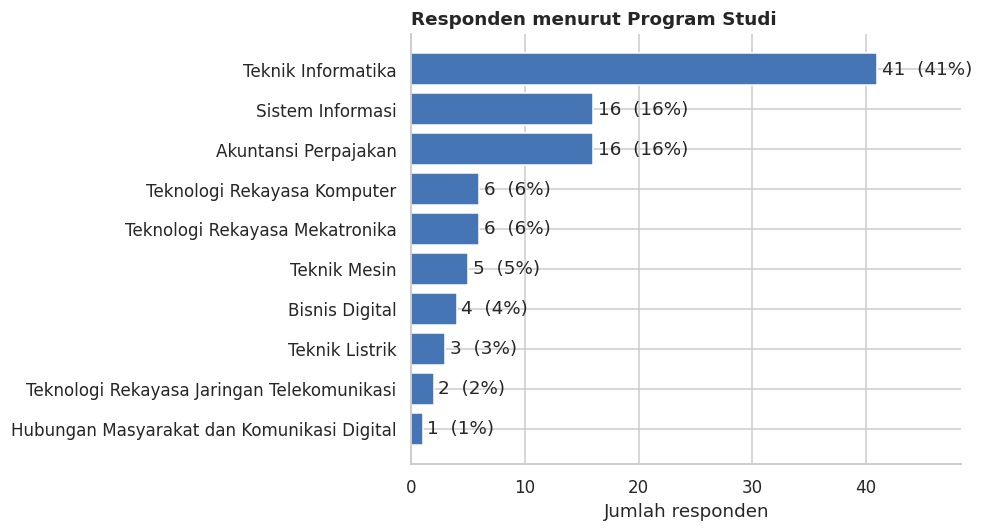

In [ ]:
data = d["program_studi"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(data.index, data.values, color="#4575b4")
ax.bar_label(bars, labels=[f"{v}  ({v/len(d)*100:.0f}%)" for v in data.values], padding=3)
ax.set_xlim(0, data.max() * 1.18)
ax.set_xlabel("Jumlah responden")
ax.set_title("Responden menurut Program Studi", fontweight="bold", loc="left")
plt.tight_layout()
simpan("01_program_studi")
plt.show()

#### Chart 2 — Donut chart jenis kelamin dan bar chart semester

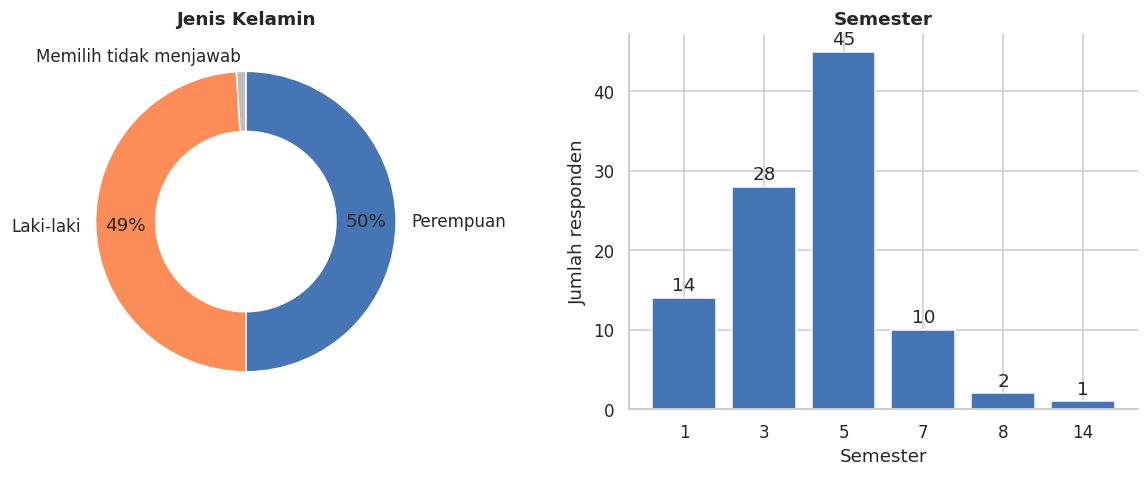

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Donut: jenis kelamin
jk = d["jenis_kelamin"].value_counts()
warna = ["#4575b4", "#fc8d59", "#bdbdbd"][:len(jk)]
ax1.pie(jk.values, labels=jk.index, colors=warna, startangle=90, counterclock=False,
        autopct=lambda p: f"{p:.0f}%" if p >= 3 else "",
        pctdistance=0.8, wedgeprops=dict(width=0.4, edgecolor="white"))
ax1.set_title("Jenis Kelamin", fontweight="bold")

# Bar: semester
sem = d["semester"].value_counts().sort_index()
bars = ax2.bar(sem.index.astype(str), sem.values, color="#4575b4")
ax2.bar_label(bars, padding=2)
ax2.set_xlabel("Semester")
ax2.set_ylabel("Jumlah responden")
ax2.set_title("Semester", fontweight="bold")

plt.tight_layout()
simpan("02_jenis_kelamin_semester")
plt.show()

### B. Pola tidur

#### Chart 3 — Histogram: durasi tidur

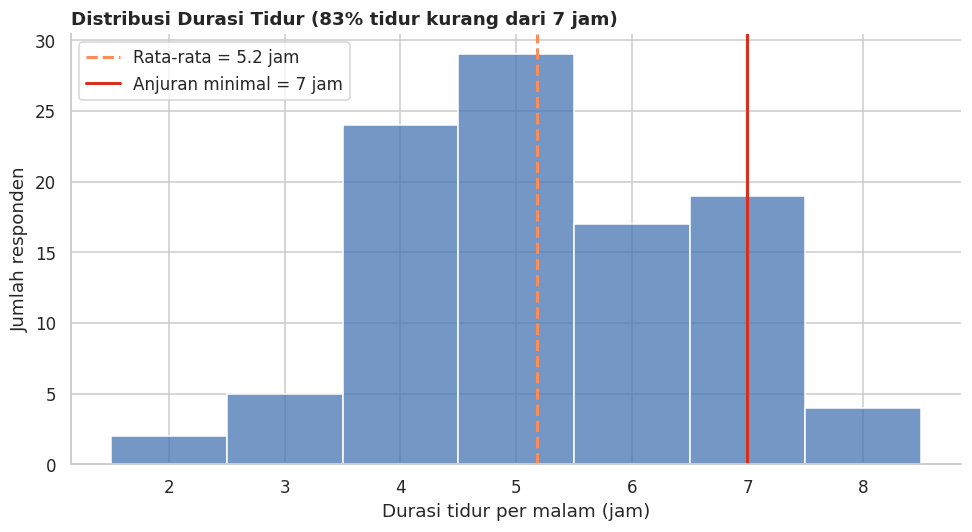

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(d["durasi_tidur_jam"], bins=np.arange(1.5, 9.5, 1), color="#4575b4",
             edgecolor="white", ax=ax)

rata = d["durasi_tidur_jam"].mean()
ax.axvline(rata, color="#fc8d59", lw=2, ls="--", label=f"Rata-rata = {rata:.1f} jam")
ax.axvline(7, color="#d7301f", lw=2, label="Anjuran minimal = 7 jam")

kurang = (d["durasi_tidur_jam"] < 7).mean() * 100
ax.set_xlabel("Durasi tidur per malam (jam)")
ax.set_ylabel("Jumlah responden")
ax.set_title(f"Distribusi Durasi Tidur ({kurang:.0f}% tidur kurang dari 7 jam)",
             fontweight="bold", loc="left")
ax.legend()
plt.tight_layout()
simpan("03_histogram_durasi_tidur")
plt.show()

#### Chart 4 — Bar chart: distribusi kualitas tidur (skor 1–5)

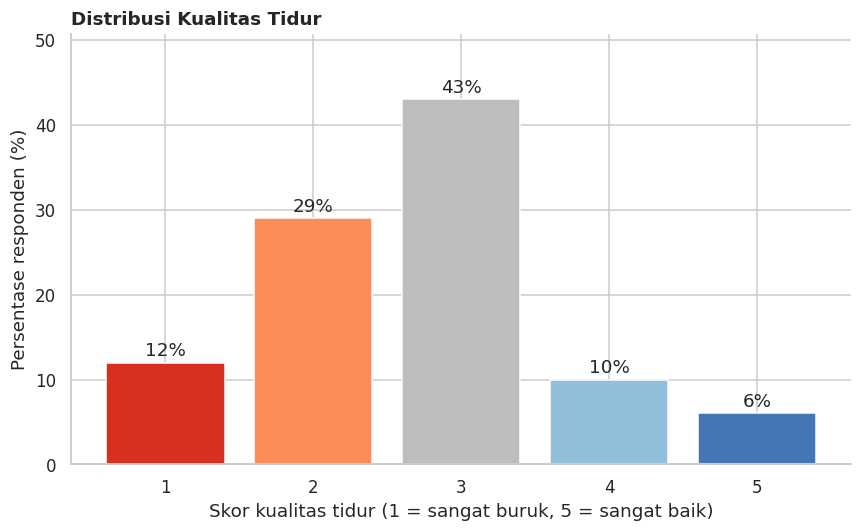

In [ ]:
pct = d["kualitas_tidur"].value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(pct.index.astype(str), pct.values,
              color=["#d7301f", "#fc8d59", "#bdbdbd", "#91bfdb", "#4575b4"])
ax.bar_label(bars, fmt="%.0f%%", padding=2)
ax.set_xlabel("Skor kualitas tidur (1 = sangat buruk, 5 = sangat baik)")
ax.set_ylabel("Persentase responden (%)")
ax.set_ylim(0, pct.max() * 1.18)
ax.set_title("Distribusi Kualitas Tidur", fontweight="bold", loc="left")
plt.tight_layout()
simpan("04_kualitas_tidur")
plt.show()

#### Chart 5 — Bar chart horizontal: faktor penyebab tidur larut

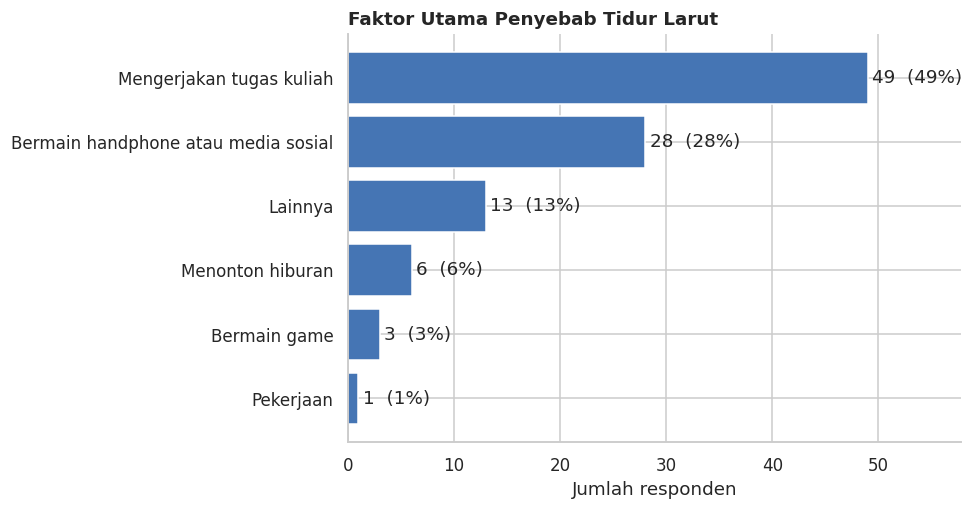

In [ ]:
data = d["faktor_tidur_larut"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(data.index, data.values, color="#4575b4")
ax.bar_label(bars, labels=[f"{v}  ({v/len(d)*100:.0f}%)" for v in data.values], padding=3)
ax.set_xlim(0, data.max() * 1.18)
ax.set_xlabel("Jumlah responden")
ax.set_title("Faktor Utama Penyebab Tidur Larut", fontweight="bold", loc="left")
plt.tight_layout()
simpan("05_faktor_tidur_larut")
plt.show()

#### Chart 6 — Boxplot: gadget, kafein, tidur siang, jam belajar
Boxplot dipilih karena variabel-variabel ini punya outlier ekstrem. Titik di luar kotak adalah outlier.

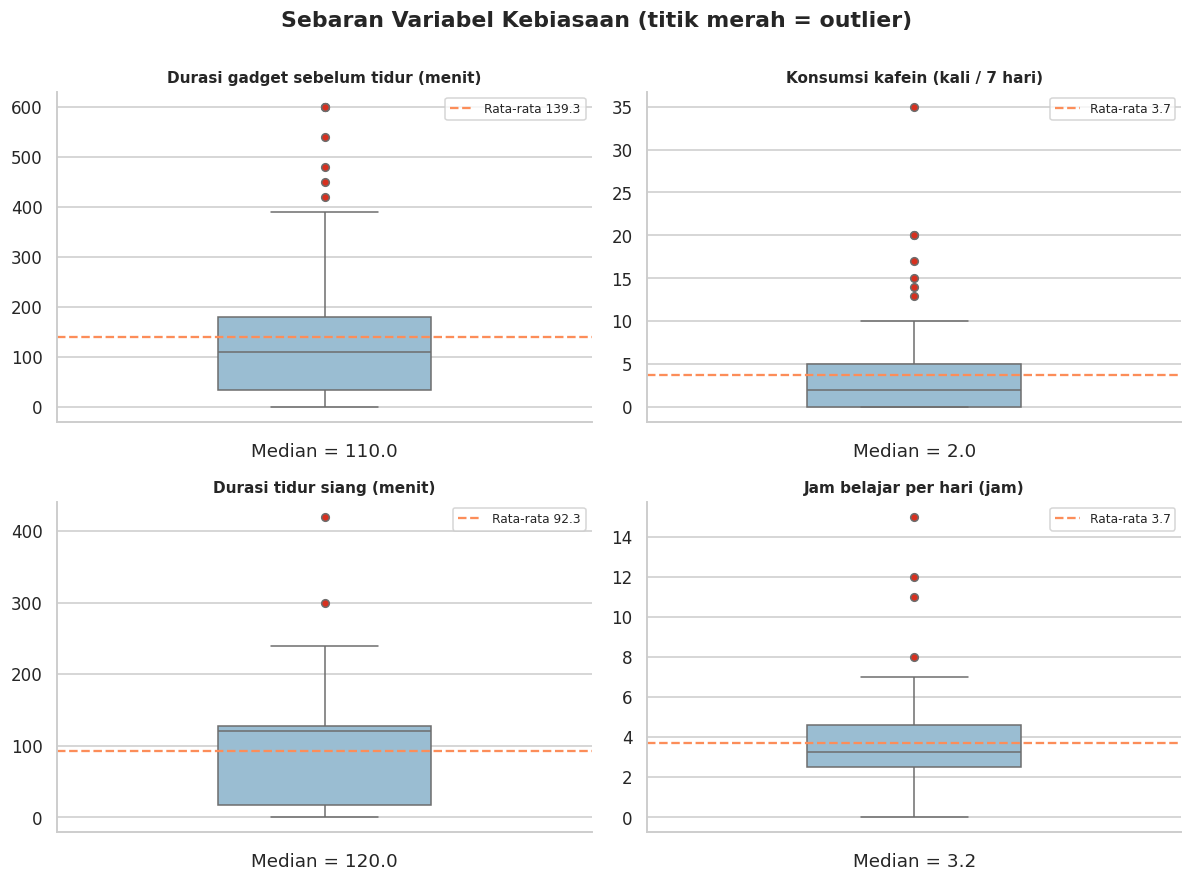

In [ ]:
var_box = {
    "durasi_gadget_menit":      "Durasi gadget sebelum tidur (menit)",
    "konsumsi_kafein_kali":     "Konsumsi kafein (kali / 7 hari)",
    "durasi_tidur_siang_menit": "Durasi tidur siang (menit)",
    "jam_belajar_per_hari":     "Jam belajar per hari (jam)",
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (kol, judul) in zip(axes.ravel(), var_box.items()):
    sns.boxplot(y=d[kol], ax=ax, color="#91bfdb", width=0.4,
                flierprops=dict(marker="o", markerfacecolor="#d7301f", markersize=5))
    ax.axhline(d[kol].mean(), color="#fc8d59", ls="--", lw=1.5,
               label=f"Rata-rata {d[kol].mean():.1f}")
    ax.set_title(judul, fontweight="bold", fontsize=10)
    ax.set_ylabel("")
    ax.set_xlabel(f"Median = {d[kol].median():.1f}")
    ax.legend(loc="upper right", fontsize=8)

fig.suptitle("Sebaran Variabel Kebiasaan (titik merah = outlier)", fontweight="bold", y=1.0)
plt.tight_layout()
simpan("06_boxplot_kebiasaan")
plt.show()

### C. Kondisi dan performa akademik

#### Chart 7 — Diverging stacked bar 100%: pertanyaan Likert (p1–p7)
Skor 1–2 (negatif) ke kiri, skor 3 (netral) di tengah, skor 4–5 (positif) ke kanan.

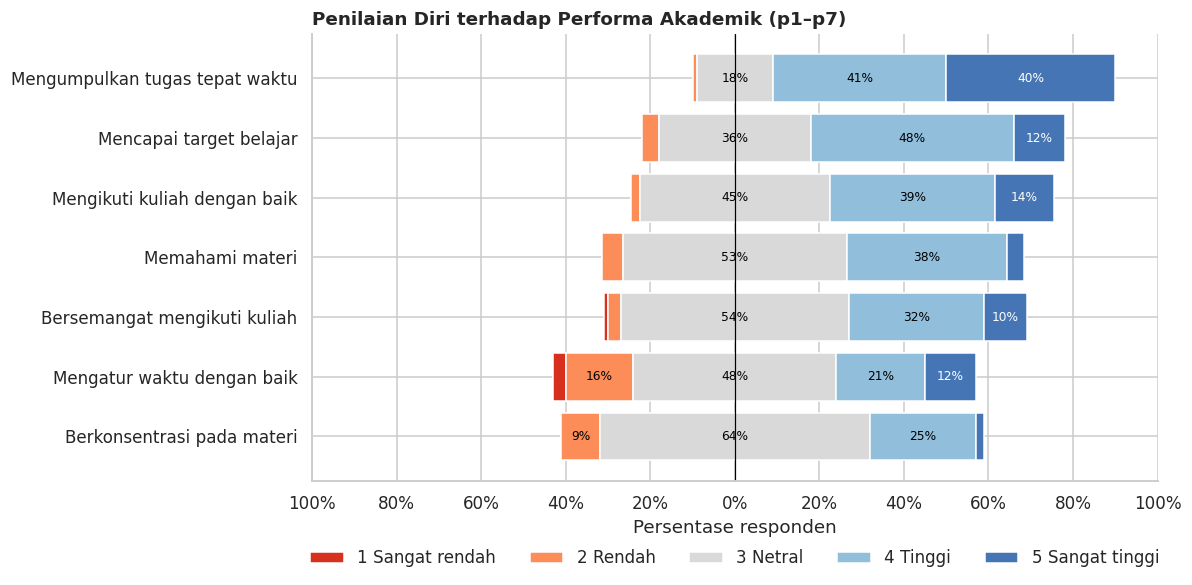

In [ ]:
warna_skor = {1: "#d7301f", 2: "#fc8d59", 3: "#d9d9d9", 4: "#91bfdb", 5: "#4575b4"}
nama_skor  = {1: "1 Sangat rendah", 2: "2 Rendah", 3: "3 Netral", 4: "4 Tinggi", 5: "5 Sangat tinggi"}

pct = pd.DataFrame({
    label_likert[c]: d[c].value_counts(normalize=True).reindex([1, 2, 3, 4, 5], fill_value=0) * 100
    for c in kol_likert
}).T

# Urutkan dari persentase positif (skor 4+5) terkecil ke terbesar
pct = pct.loc[(pct[4] + pct[5]).sort_values().index]

kiri = -(pct[1] + pct[2] + pct[3] / 2)

fig, ax = plt.subplots(figsize=(11, 5.5))
for s in [1, 2, 3, 4, 5]:
    ax.barh(pct.index, pct[s], left=kiri, color=warna_skor[s], label=nama_skor[s],
            edgecolor="white")
    for y, (mulai, lebar) in enumerate(zip(kiri, pct[s])):
        if lebar >= 7:
            ax.text(mulai + lebar / 2, y, f"{lebar:.0f}%", ha="center", va="center",
                    fontsize=8, color="white" if s in (1, 5) else "black")
    kiri = kiri + pct[s]

ax.axvline(0, color="black", lw=0.8)
batas = int(np.ceil(max((pct[1] + pct[2] + pct[3] / 2).max(), (pct[4] + pct[5] + pct[3] / 2).max()) / 10) * 10) + 10
ax.set_xlim(-batas, batas)
ax.set_xticks(np.arange(-batas, batas + 1, 20))
ax.set_xticklabels([f"{abs(t)}%" for t in np.arange(-batas, batas + 1, 20)])
ax.set_xlabel("Persentase responden")
ax.set_title("Penilaian Diri terhadap Performa Akademik (p1–p7)", fontweight="bold", loc="left")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout()
simpan("07_likert_diverging")
plt.show()

#### Chart 8 — Bar chart rata-rata: gejala kelelahan

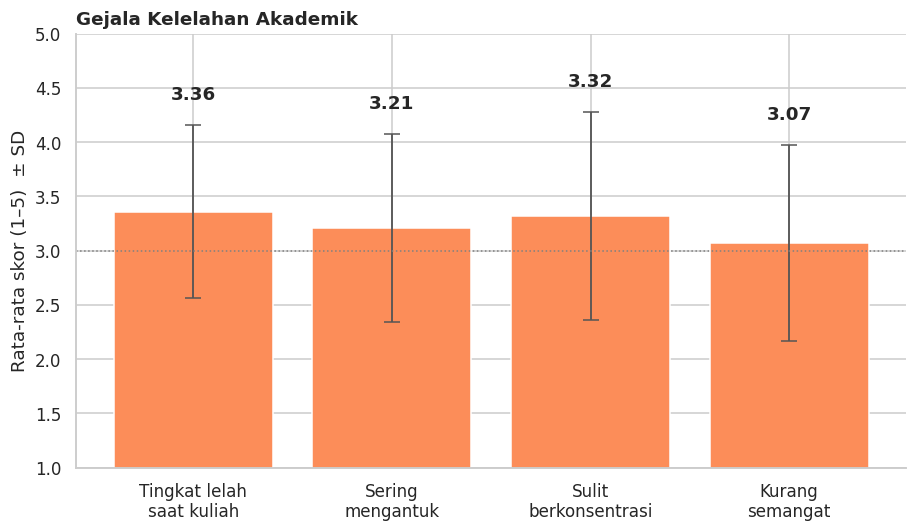

In [ ]:
label_gejala = {
    "tingkat_lelah_kuliah": "Tingkat lelah\nsaat kuliah",
    "sering_mengantuk":     "Sering\nmengantuk",
    "sulit_konsentrasi":    "Sulit\nberkonsentrasi",
    "kurang_semangat":      "Kurang\nsemangat",
}
rata = d[list(label_gejala)].mean()
sd   = d[list(label_gejala)].std()

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.bar(list(label_gejala.values()), rata.values, yerr=sd.values, capsize=5,
              color="#fc8d59", error_kw=dict(ecolor="#555555", lw=1.2))
ax.bar_label(bars, labels=[f"{v:.2f}" for v in rata.values], padding=14, fontweight="bold")
ax.set_ylim(1, 5)
ax.axhline(3, color="grey", ls=":", lw=1)
ax.set_ylabel("Rata-rata skor (1–5)  ± SD")
ax.set_title("Gejala Kelelahan Akademik", fontweight="bold", loc="left")
plt.tight_layout()
simpan("08_gejala_kelelahan")
plt.show()

### D. Hubungan antarvariabel

#### Chart 9 — Scatter plot + garis tren: durasi tidur vs skor performa
Titik diberi sedikit *jitter* supaya titik yang bertumpuk tetap terlihat. Korelasi dihitung dari data asli.

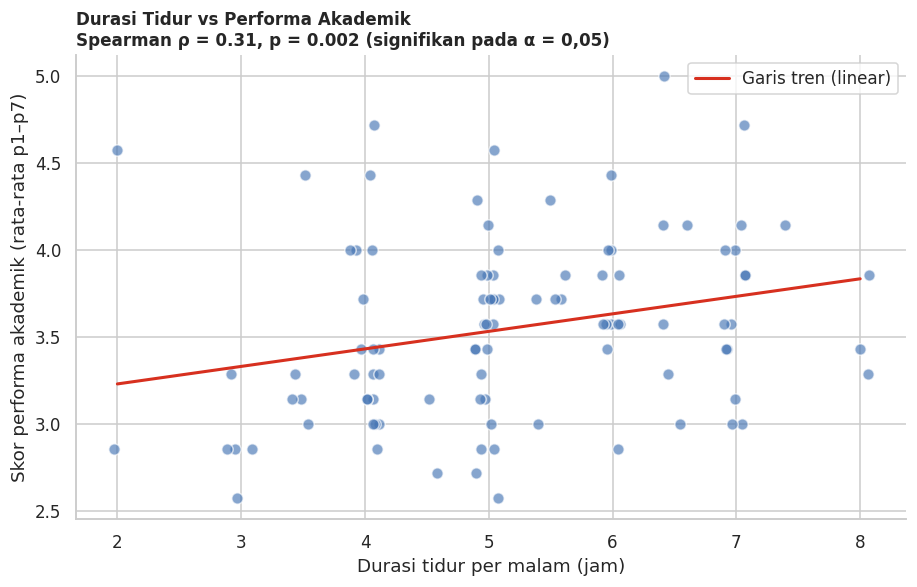

In [ ]:
x, y = d["durasi_tidur_jam"], d["skor_performa"]
rho, p = spearmanr(x, y)

rng = np.random.default_rng(42)
xj = x + rng.uniform(-0.12, 0.12, len(x))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(xj, y, alpha=0.65, color="#4575b4", edgecolor="white", s=55)

koef = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, np.polyval(koef, xs), color="#d7301f", lw=2, label="Garis tren (linear)")

ax.set_xlabel("Durasi tidur per malam (jam)")
ax.set_ylabel("Skor performa akademik (rata-rata p1–p7)")
signif = "signifikan" if p < 0.05 else "tidak signifikan"
ax.set_title(f"Durasi Tidur vs Performa Akademik\nSpearman ρ = {rho:.2f}, p = {p:.3f} ({signif} pada α = 0,05)",
             fontweight="bold", loc="left", fontsize=11)
ax.legend()
plt.tight_layout()
simpan("09_scatter_tidur_performa")
plt.show()

#### Chart 10 — Boxplot per kelompok
(a) Skor performa menurut kategori kualitas tidur. (b) Durasi tidur menurut faktor tidur larut.
Jumlah responden (n) ditampilkan di label, jadi kelompok yang kecil mudah dikenali.

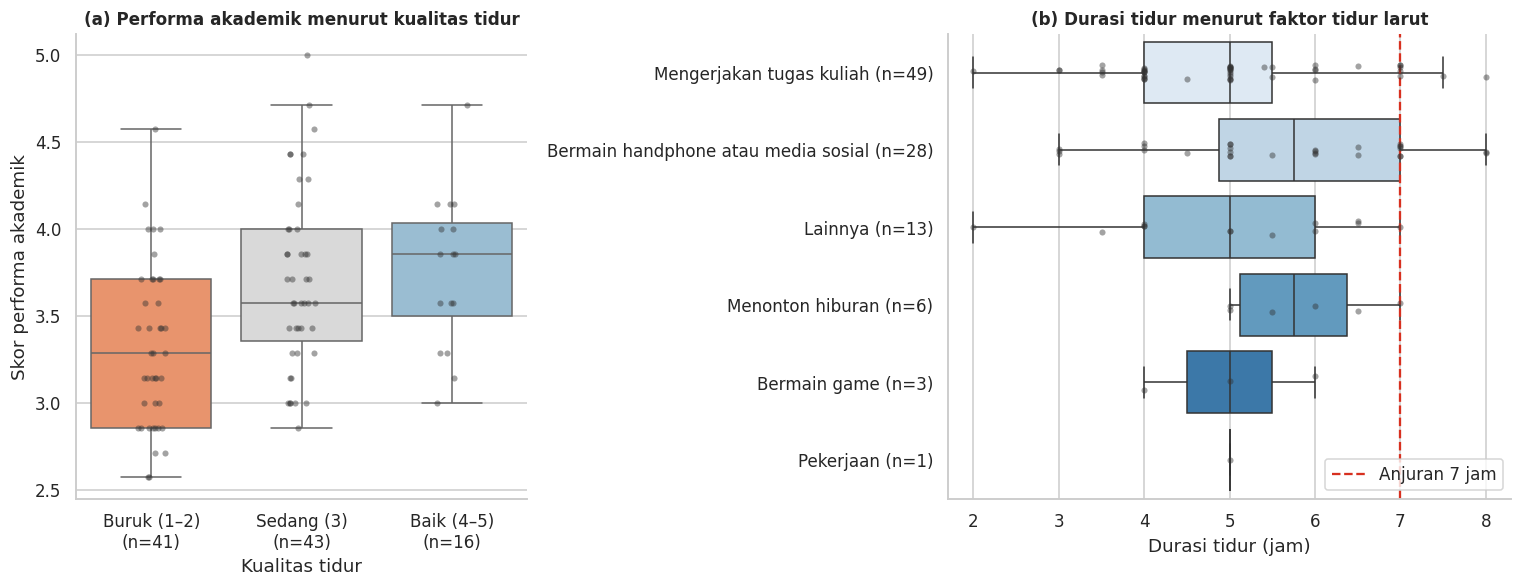

Catatan: kelompok dengan n sangat kecil (mis. n < 5) tidak cukup kuat untuk disimpulkan.


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})

# (a) Skor performa menurut kualitas tidur
urut = ["Buruk (1–2)", "Sedang (3)", "Baik (4–5)"]
n_kual = d["kategori_kualitas"].value_counts()
d["kualitas_label"] = d["kategori_kualitas"].astype(str) + "\n(n=" + d["kategori_kualitas"].map(n_kual).astype(str) + ")"
urut_label = [f"{u}\n(n={n_kual[u]})" for u in urut]

sns.boxplot(data=d, x="kualitas_label", y="skor_performa", order=urut_label,
            hue="kualitas_label", hue_order=urut_label, legend=False,
            palette=["#fc8d59", "#d9d9d9", "#91bfdb"], ax=ax1, showfliers=False)
sns.stripplot(data=d, x="kualitas_label", y="skor_performa", order=urut_label,
              color="#333333", alpha=0.45, size=4, ax=ax1)
ax1.set_xlabel("Kualitas tidur")
ax1.set_ylabel("Skor performa akademik")
ax1.set_title("(a) Performa akademik menurut kualitas tidur", fontweight="bold", fontsize=11)

# (b) Durasi tidur menurut faktor tidur larut
n_f = d["faktor_tidur_larut"].value_counts()
d["faktor_label"] = d["faktor_tidur_larut"] + " (n=" + d["faktor_tidur_larut"].map(n_f).astype(str) + ")"
urut_f = [f"{k} (n={v})" for k, v in n_f.items()]

sns.boxplot(data=d, y="faktor_label", x="durasi_tidur_jam", order=urut_f,
            hue="faktor_label", hue_order=urut_f, legend=False, palette="Blues", ax=ax2, showfliers=False)
sns.stripplot(data=d, y="faktor_label", x="durasi_tidur_jam", order=urut_f,
              color="#333333", alpha=0.45, size=4, ax=ax2)
ax2.axvline(7, color="#d7301f", ls="--", lw=1.5, label="Anjuran 7 jam")
ax2.set_xlabel("Durasi tidur (jam)")
ax2.set_ylabel("")
ax2.set_title("(b) Durasi tidur menurut faktor tidur larut", fontweight="bold", fontsize=11)
ax2.legend(loc="lower right")

plt.tight_layout()
simpan("10_boxplot_kelompok")
plt.show()

print("Catatan: kelompok dengan n sangat kecil (mis. n < 5) tidak cukup kuat untuk disimpulkan.")

#### Chart 11 — Heatmap korelasi (Spearman)
Warna biru = korelasi positif, merah = negatif. Spearman dipilih karena banyak variabel berskala ordinal dan ada outlier.

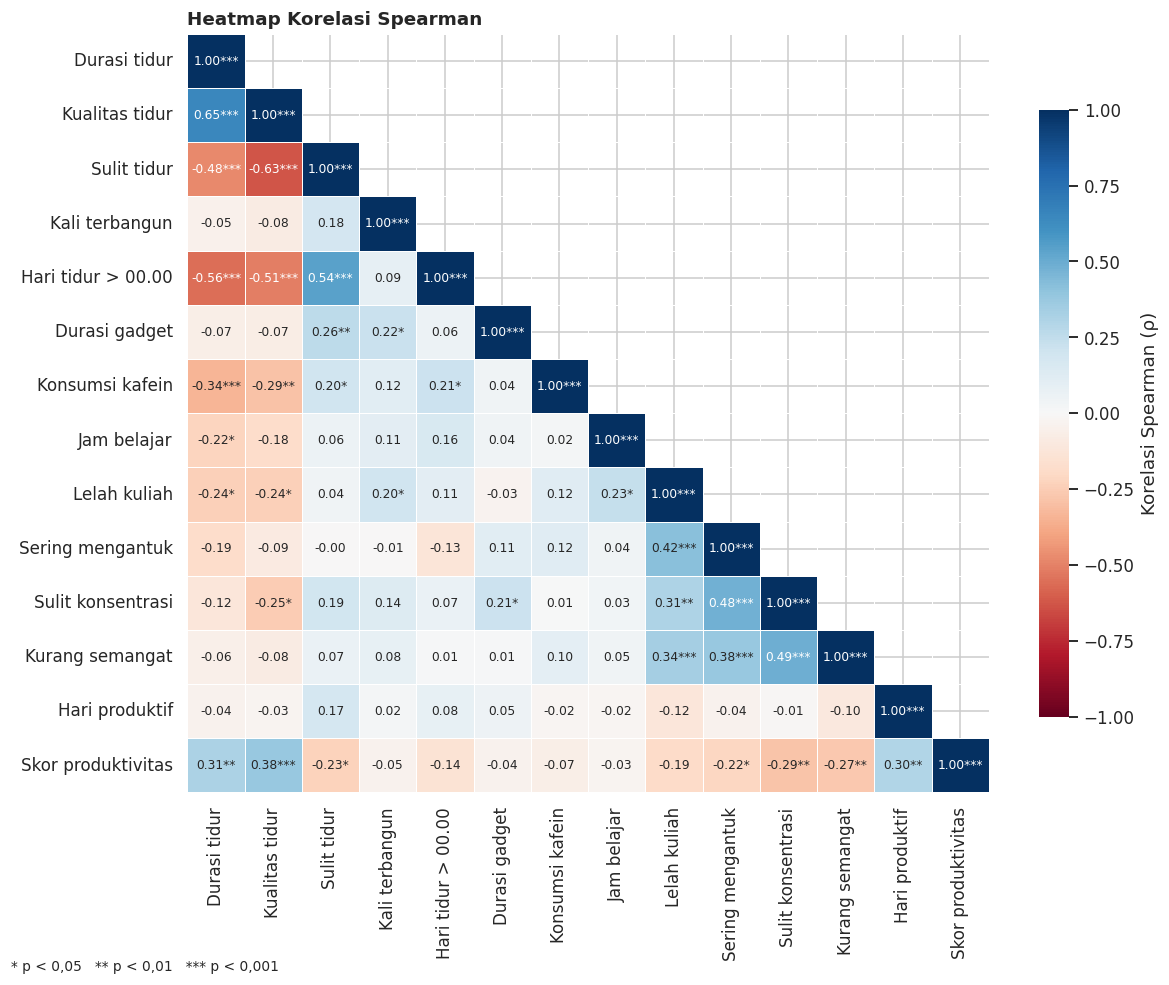

                     rho  p_value Signifikan (p<0,05)
Kualitas tidur      0.38     0.00                  Ya
Durasi tidur        0.31     0.00                  Ya
Hari produktif      0.30     0.00                  Ya
Sulit konsentrasi  -0.29     0.00                  Ya
Kurang semangat    -0.27     0.01                  Ya
Sulit tidur        -0.23     0.02                  Ya
Sering mengantuk   -0.22     0.03                  Ya
Lelah kuliah       -0.19     0.06               Tidak
Hari tidur > 00.00 -0.14     0.16               Tidak
Konsumsi kafein    -0.07     0.51               Tidak
Kali terbangun     -0.05     0.65               Tidak
Durasi gadget      -0.04     0.67               Tidak
Jam belajar        -0.03     0.79               Tidak


In [ ]:
from scipy.stats import spearmanr

kol_korelasi = {
    "durasi_tidur_jam": "Durasi tidur",
    "kualitas_tidur": "Kualitas tidur",
    "sulit_tidur": "Sulit tidur",
    "kali_terbangun": "Kali terbangun",
    "hari_tidur_lewat_00": "Hari tidur > 00.00",
    "durasi_gadget_menit": "Durasi gadget",
    "konsumsi_kafein_kali": "Konsumsi kafein",
    "jam_belajar_per_hari": "Jam belajar",
    "tingkat_lelah_kuliah": "Lelah kuliah",
    "sering_mengantuk": "Sering mengantuk",
    "sulit_konsentrasi": "Sulit konsentrasi",
    "kurang_semangat": "Kurang semangat",
    "hari_produktif": "Hari produktif",
    "skor_performa": "Skor produktivitas",   # label diganti
}
kolom = list(kol_korelasi)
label = list(kol_korelasi.values())

# rho dan p-value sekaligus
rho, pval = spearmanr(d[kolom])
korelasi = pd.DataFrame(rho, index=label, columns=label)
pvalue = pd.DataFrame(pval, index=label, columns=label)

def bintang(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

n = len(label)
anot = np.array([[f"{korelasi.iloc[i, j]:.2f}{bintang(pvalue.iloc[i, j])}"
                  for j in range(n)] for i in range(n)])
mask = np.triu(np.ones_like(korelasi, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(korelasi, mask=mask, annot=anot, fmt="", cmap="RdBu", vmin=-1, vmax=1,
            center=0, linewidths=0.5, annot_kws={"size": 8},
            cbar_kws={"label": "Korelasi Spearman (ρ)", "shrink": 0.8}, ax=ax)
ax.set_title("Heatmap Korelasi Spearman", fontweight="bold", loc="left")
fig.text(0.01, 0.01, "* p < 0,05   ** p < 0,01   *** p < 0,001", fontsize=9)
plt.tight_layout()
simpan("11_heatmap_korelasi")
plt.show()

# Tabel korelasi terhadap skor produktivitas (untuk dimasukkan ke laporan)
tabel = pd.DataFrame({
    "rho": korelasi["Skor produktivitas"],
    "p_value": pvalue["Skor produktivitas"],
}).drop("Skor produktivitas")
tabel["Signifikan (p<0,05)"] = np.where(tabel["p_value"] < 0.05, "Ya", "Tidak")
tabel = tabel.sort_values("rho", key=abs, ascending=False)
print(tabel.round(4))

#### Tambahan — Tabel korelasi dengan skor performa (beserta p-value)
Membantu memastikan korelasi mana yang benar-benar signifikan secara statistik.

In [ ]:
baris = []
for kol, nama in kol_korelasi.items():
    if kol == "skor_performa":
        continue
    rho, p = spearmanr(d[kol], d["skor_performa"])
    baris.append({"variabel": nama, "rho": rho, "p_value": p,
                  "signifikan (p<0,05)": "Ya" if p < 0.05 else "Tidak"})

tabel_kor = (pd.DataFrame(baris)
             .assign(abs_rho=lambda t: t["rho"].abs())
             .sort_values("abs_rho", ascending=False)
             .drop(columns="abs_rho")
             .set_index("variabel"))
display(tabel_kor)

,rho,p_value,"signifikan (p<0,05)"
variabel,,,
Kualitas tidur,0.38,0.00,Ya
Durasi tidur,0.31,0.00,Ya
Hari produktif,0.30,0.00,Ya
Sulit konsentrasi,-0.29,0.00,Ya
Kurang semangat,-0.27,0.01,Ya
Sulit tidur,-0.23,0.02,Ya
Sering mengantuk,-0.22,0.03,Ya
Lelah kuliah,-0.19,0.06,Tidak
Hari tidur > 00.00,-0.14,0.16,Tidak


## Bagian 3 — Unduh semua chart

In [ ]:
import shutil
shutil.make_archive("semua_chart", "zip", "grafik")

try:
    from google.colab import files
    files.download("semua_chart.zip")
except ImportError:
    print("Semua chart tersimpan di folder 'grafik' dan file semua_chart.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>